In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt


In [9]:
# Data loading and augmentation
transform_train = transforms.Compose([
    transforms.RandomHorizontalFlip(),  # Horizontal flip
    transforms.RandomRotation(10),      # Random rotation
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

trainset = torchvision.datasets.FashionMNIST(
    root='./data', train=True, download=True, transform=transform_train)
trainloader = torch.utils.data.DataLoader(
    trainset, batch_size=64, shuffle=True)

testset = torchvision.datasets.FashionMNIST(
    root='./data', train=False, download=True, transform=transform_test)
testloader = torch.utils.data.DataLoader(testset, batch_size=64, shuffle=False)


In [10]:
# Define the model with 2 hidden layers
class Model2Hidden(nn.Module):
    def __init__(self):
        super(Model2Hidden, self).__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(28*28, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 10)
        self.relu = nn.ReLU()
        self.softmax = nn.Softmax(dim=1)

    def forward(self, x):
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.softmax(self.fc3(x))
        return x


In [11]:
# Training function
def train(model, trainloader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in trainloader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()

        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(trainloader)
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

# Validation function


def validate(model, testloader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in testloader:
            inputs, labels = inputs.to(device), labels.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_loss = running_loss / len(testloader)
    val_acc = correct / total
    return val_loss, val_acc


In [12]:
# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Model, loss function, optimizer
model = Model2Hidden().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

num_epochs = 10
train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []

for epoch in range(num_epochs):
    train_loss, train_acc = train(
        model, trainloader, criterion, optimizer, device)
    val_loss, val_acc = validate(model, testloader, criterion, device)

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    print(f'Epoch {epoch+1}/{num_epochs}, Loss: {train_loss:.4f}, Accuracy: {
          train_acc:.4f}, Val Loss: {val_loss:.4f}, Val Accuracy: {val_acc:.4f}')


Epoch 1/10, Loss: 1.7449, Accuracy: 0.7228, Val Loss: 1.6719, Val Accuracy: 0.7908
Epoch 2/10, Loss: 1.6595, Accuracy: 0.8026, Val Loss: 1.6637, Val Accuracy: 0.7978
Epoch 3/10, Loss: 1.6470, Accuracy: 0.8144, Val Loss: 1.6577, Val Accuracy: 0.8031
Epoch 4/10, Loss: 1.6383, Accuracy: 0.8227, Val Loss: 1.6478, Val Accuracy: 0.8122
Epoch 5/10, Loss: 1.6314, Accuracy: 0.8298, Val Loss: 1.6411, Val Accuracy: 0.8192
Epoch 6/10, Loss: 1.6301, Accuracy: 0.8305, Val Loss: 1.6314, Val Accuracy: 0.8286
Epoch 7/10, Loss: 1.6254, Accuracy: 0.8351, Val Loss: 1.6275, Val Accuracy: 0.8330
Epoch 8/10, Loss: 1.6228, Accuracy: 0.8380, Val Loss: 1.6265, Val Accuracy: 0.8338
Epoch 9/10, Loss: 1.6188, Accuracy: 0.8418, Val Loss: 1.6226, Val Accuracy: 0.8385
Epoch 10/10, Loss: 1.6192, Accuracy: 0.8410, Val Loss: 1.6260, Val Accuracy: 0.8342


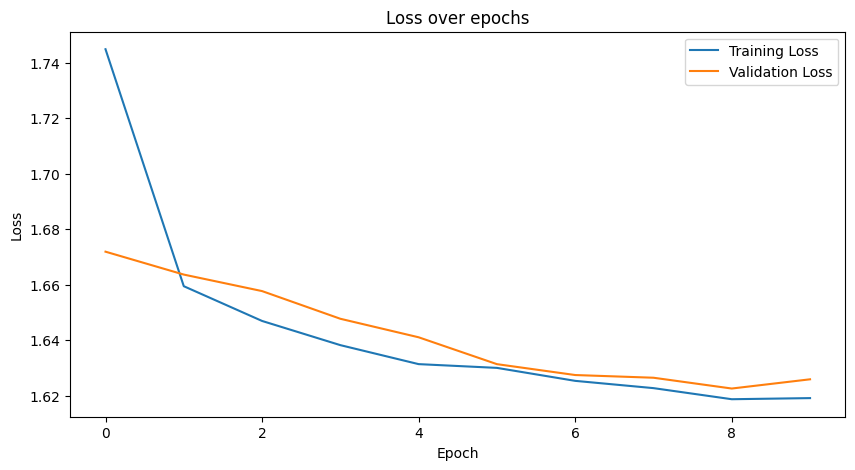

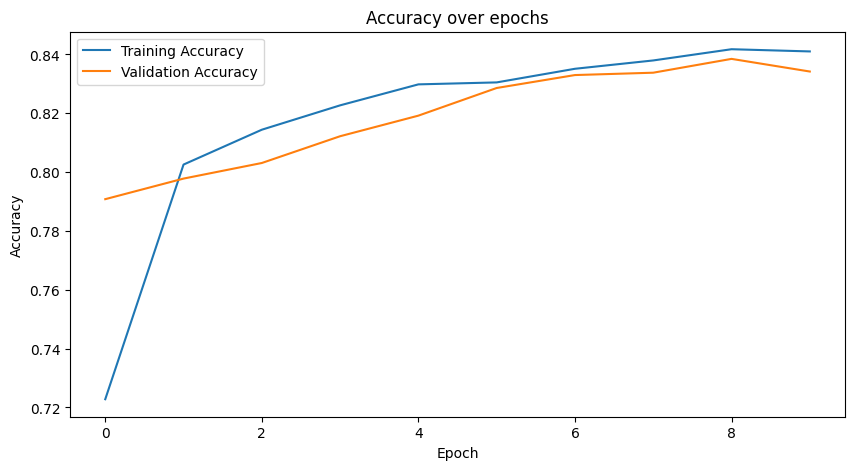

In [13]:
# Plotting loss
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('Loss over epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Plotting accuracy
plt.figure(figsize=(10, 5))
plt.plot(train_accuracies, label='Training Accuracy')
plt.plot(val_accuracies, label='Validation Accuracy')
plt.title('Accuracy over epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()
